<a href="https://colab.research.google.com/github/SarveeshK/HCL/blob/main/Unit-3/Transformer_Translation_Model.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
# Install required libraries for dataset loading, custom BPE tokenization, BLEU scoring, and plotting
!pip install -q datasets tokenizers sacrebleu torch matplotlib pandas

In [ ]:
import os
import math
import time
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader

from datasets import load_dataset
from tokenizers import Tokenizer, models, trainers, pre_tokenizers, decoders
import sacrebleu

# Fix random seeds across Python, NumPy, and PyTorch so Variant A and Variant B
# start under identical reproducible conditions
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)

# Use CUDA GPU if available (e.g., Colab T4), otherwise fall back to CPU
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Running on device: {device}")

Running on device: cuda


In [ ]:
# Load the full English-Hindi parallel dataset (~128k sentence pairs) from Hugging Face
raw_ds = load_dataset("Aarif1430/english-to-hindi", split="train")

def clean_and_filter(example, max_words=40):
    """
    Remove null/corrupted rows and filter out sentences longer than `max_words`.
    Keeping sequences <= 40 words prevents GPU memory spikes and helps a
    randomly initialized Transformer learn alignments faster.
    """
    en = example["english_sentence"]
    hi = example["hindi_sentence"]
    if not isinstance(en, str) or not isinstance(hi, str):
        return False
    en_words = en.strip().split()
    hi_words = hi.strip().split()
    return (1 <= len(en_words) <= max_words) and (1 <= len(hi_words) <= max_words)

filtered_ds = raw_ds.filter(clean_and_filter)

# Partition into 90% Train, 5% Validation, and 5% Test splits
split_1 = filtered_ds.train_test_split(test_size=0.10, seed=SEED)
split_2 = split_1["test"].train_test_split(test_size=0.50, seed=SEED)

train_data = split_1["train"]
val_data = split_2["train"]
test_data = split_2["test"]

print(f"Total Filtered Pairs : {len(filtered_ds):,}")
print(f"Train Split          : {len(train_data):,}")
print(f"Validation Split     : {len(val_data):,}")
print(f"Test Split           : {len(test_data):,}")
print("Sample Pair          :", train_data[0])

README.md:   0%|          | 0.00/2.23k [00:00<?, ?B/s]

data/train-00000-of-00001-71c2cec7402cd4(…): reconstructing file:   0%|          |  0.00B / 21.7MB            

data/train-00000-of-00001-71c2cec7402cd4(…): downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/127705 [00:00<?, ? examples/s]

Filter:   0%|          | 0/127705 [00:00<?, ? examples/s]

Total Filtered Pairs : 117,882
Train Split          : 106,093
Validation Split     : 5,894
Test Split           : 5,895
Sample Pair          : {'english_sentence': "But , in the Golaknath case , the Supreme Court ruled by a majority judgement that an Act amending the Constitution was also ' law ' under this definition and therefore subject to judicial review .", 'hindi_sentence': "लेकिन गोलकनाथ के मामले में उच्चतम न्यायालय ने बहुमत से निर्णय किया कि इस परिभाषा के अधीन संविधान-संशोधन-अधिनियम भी ' विधि ' है और इसलिए उसका न्यायिक पुनर्विलोकन किया जा सकता है ."}


In [ ]:
# Reserved control tokens:
# [PAD] -> sequence padding | [UNK] -> out-of-vocabulary subwords
# [SOS] -> start of sequence | [EOS] -> end of sequence
SPECIAL_TOKENS = ["[PAD]", "[UNK]", "[SOS]", "[EOS]"]

def train_bpe_tokenizer(dataset, column_name, vocab_size=12000):
    """
    Train a Byte-Pair Encoding (BPE) subword tokenizer strictly from scratch
    on the training split (zero pretrained vocabulary files used).
    Subword splitting handles Hindi suffixes and English inflections cleanly.
    """
    tokenizer = Tokenizer(models.BPE(unk_token="[UNK]", end_of_word_suffix="</w>"))
    tokenizer.pre_tokenizer = pre_tokenizers.Whitespace()
    tokenizer.decoder = decoders.BPEDecoder(suffix="</w>")

    trainer = trainers.BpeTrainer(
        vocab_size=vocab_size,
        special_tokens=SPECIAL_TOKENS,
        min_frequency=2,  # Ignore rare typos appearing only once
        end_of_word_suffix="</w>"
    )

    def batch_iterator():
        for row in dataset:
            yield row[column_name].strip()

    tokenizer.train_from_iterator(batch_iterator(), trainer=trainer)
    return tokenizer

# Train separate subword vocabularies for source (English) and target (Hindi)
src_tokenizer = train_bpe_tokenizer(train_data, "english_sentence", vocab_size=12000)
tgt_tokenizer = train_bpe_tokenizer(train_data, "hindi_sentence", vocab_size=12000)

# Cache special token IDs (identical across both tokenizers due to SPECIAL_TOKENS order)
PAD_IDX = src_tokenizer.token_to_id("[PAD]")
SOS_IDX = src_tokenizer.token_to_id("[SOS]")
EOS_IDX = src_tokenizer.token_to_id("[EOS]")

print(f"Custom EN BPE Vocab Size: {src_tokenizer.get_vocab_size():,}")
print(f"Custom HI BPE Vocab Size: {tgt_tokenizer.get_vocab_size():,}")

Custom EN BPE Vocab Size: 12,000
Custom HI BPE Vocab Size: 12,000


In [ ]:
MAX_LEN = 56      # Maximum subword sequence length (including [SOS] and [EOS])
BATCH_SIZE = 64   # Number of sentence pairs per gradient step

class EnHiTranslationDataset(Dataset):
    """Wraps a Hugging Face dataset split and converts text pairs into token ID tensors."""
    def __init__(self, hf_split, src_tok, tgt_tok, max_len=MAX_LEN):
        self.data = hf_split
        self.src_tok = src_tok
        self.tgt_tok = tgt_tok
        self.max_len = max_len

    def __len__(self):
        return len(self.data)

    def __getitem__(self, idx):
        row = self.data[idx]
        # Encode text, truncate to (max_len - 2), and wrap with [SOS] and [EOS]
        src_ids = [SOS_IDX] + self.src_tok.encode(row["english_sentence"].strip()).ids[:self.max_len - 2] + [EOS_IDX]
        tgt_ids = [SOS_IDX] + self.tgt_tok.encode(row["hindi_sentence"].strip()).ids[:self.max_len - 2] + [EOS_IDX]
        return torch.tensor(src_ids, dtype=torch.long), torch.tensor(tgt_ids, dtype=torch.long)

def collate_fn(batch):
    """
    Dynamically pads sequences in a batch to the longest sequence in that batch
    rather than padding every batch to MAX_LEN, speeding up attention computation.
    """
    src_batch, tgt_batch = zip(*batch)
    src_padded = nn.utils.rnn.pad_sequence(src_batch, batch_first=True, padding_value=PAD_IDX)
    tgt_padded = nn.utils.rnn.pad_sequence(tgt_batch, batch_first=True, padding_value=PAD_IDX)
    return src_padded, tgt_padded

# Create DataLoaders (shuffle training batches; keep val/test deterministic)
train_loader = DataLoader(EnHiTranslationDataset(train_data, src_tokenizer, tgt_tokenizer), batch_size=BATCH_SIZE, shuffle=True, collate_fn=collate_fn)
val_loader   = DataLoader(EnHiTranslationDataset(val_data, src_tokenizer, tgt_tokenizer), batch_size=BATCH_SIZE, shuffle=False, collate_fn=collate_fn)
test_loader  = DataLoader(EnHiTranslationDataset(test_data, src_tokenizer, tgt_tokenizer), batch_size=BATCH_SIZE, shuffle=False, collate_fn=collate_fn)

In [ ]:
class PositionalEncoding(nn.Module):
    """
    Injects deterministic sinusoidal position signals into token embeddings so the
    self-attention layers know token order without recurrence.
    """
    def __init__(self, d_model: int, dropout: float = 0.1, max_len: int = 512):
        super().__init__()
        self.dropout = nn.Dropout(p=dropout)

        # Compute sine (even indices) and cosine (odd indices) waves across positions
        pe = torch.zeros(max_len, d_model)
        position = torch.arange(0, max_len, dtype=torch.float).unsqueeze(1)
        div_term = torch.exp(torch.arange(0, d_model, 2).float() * (-math.log(10000.0) / d_model))
        pe[:, 0::2] = torch.sin(position * div_term)
        pe[:, 1::2] = torch.cos(position * div_term)

        # Register as non-trainable buffer so it moves automatically with model.to(device)
        self.register_buffer("pe", pe.unsqueeze(0))  # Shape: (1, max_len, d_model)

    def forward(self, x):
        # Add positional encoding up to current sequence length and apply dropout
        x = x + self.pe[:, :x.size(1), :]
        return self.dropout(x)


class Seq2SeqTransformer(nn.Module):
    """
    Encoder-Decoder Transformer built from scratch using PyTorch primitives.
    All embedding, attention, and feed-forward weights are Xavier-initialized.
    """
    def __init__(
        self,
        num_encoder_layers: int,
        num_decoder_layers: int,
        d_model: int,
        nhead: int,
        src_vocab_size: int,
        tgt_vocab_size: int,
        dim_feedforward: int = 1024,
        dropout: float = 0.1,
    ):
        super().__init__()
        self.d_model = d_model

        # Learned source and target lookup tables (padding index stays zeroed)
        self.src_tok_emb = nn.Embedding(src_vocab_size, d_model, padding_idx=PAD_IDX)
        self.tgt_tok_emb = nn.Embedding(tgt_vocab_size, d_model, padding_idx=PAD_IDX)
        self.positional_encoding = PositionalEncoding(d_model, dropout=dropout)

        # Core Multi-Head Attention Encoder-Decoder stack
        self.transformer = nn.Transformer(
            d_model=d_model,
            nhead=nhead,
            num_encoder_layers=num_encoder_layers,
            num_decoder_layers=num_decoder_layers,
            dim_feedforward=dim_feedforward,
            dropout=dropout,
            batch_first=True,  # Expects (batch, seq_len, d_model) tensors
        )

        # Final linear projection from hidden dimension to target vocabulary logits
        self.generator = nn.Linear(d_model, tgt_vocab_size)
        self._init_weights()

    def _init_weights(self):
        """Initialize all 2D+ weight matrices using Xavier Uniform distribution."""
        for p in self.parameters():
            if p.dim() > 1:
                nn.init.xavier_uniform_(p)

    def forward(self, src, tgt):
        # Boolean causal mask (True = masked future position) matching bool padding masks
        tgt_len = tgt.size(1)
        tgt_mask = torch.triu(
            torch.ones((tgt_len, tgt_len), device=src.device, dtype=torch.bool),
            diagonal=1,
        )

        # Boolean padding masks tell attention layers to ignore [PAD] tokens
        src_pad_mask = (src == PAD_IDX)
        tgt_pad_mask = (tgt == PAD_IDX)

        # Scale embeddings by sqrt(d_model) before adding positional encodings (Vaswani et al.)
        src_emb = self.positional_encoding(self.src_tok_emb(src) * math.sqrt(self.d_model))
        tgt_emb = self.positional_encoding(self.tgt_tok_emb(tgt) * math.sqrt(self.d_model))

        outs = self.transformer(
            src=src_emb,
            tgt=tgt_emb,
            tgt_mask=tgt_mask,
            src_key_padding_mask=src_pad_mask,
            tgt_key_padding_mask=tgt_pad_mask,
            memory_key_padding_mask=src_pad_mask,
        )
        return self.generator(outs)

    @torch.no_grad()
    def encode(self, src):
        """Run encoder pass once during inference to produce contextual memory states."""
        src_pad_mask = (src == PAD_IDX)
        src_emb = self.positional_encoding(self.src_tok_emb(src) * math.sqrt(self.d_model))
        return self.transformer.encoder(src_emb, src_key_padding_mask=src_pad_mask), src_pad_mask

    @torch.no_grad()
    def decode(self, tgt, memory, memory_key_padding_mask):
        """Run single autoregressive decoder step conditioned on encoder memory."""
        tgt_len = tgt.size(1)
        tgt_mask = torch.triu(
            torch.ones((tgt_len, tgt_len), device=tgt.device, dtype=torch.bool),
            diagonal=1,
        )
        tgt_emb = self.positional_encoding(self.tgt_tok_emb(tgt) * math.sqrt(self.d_model))
        return self.transformer.decoder(
            tgt_emb,
            memory,
            tgt_mask=tgt_mask,
            memory_key_padding_mask=memory_key_padding_mask,
        )

In [ ]:
def train_and_evaluate_variant(variant_name, num_layers, nhead, epochs=12, lr=5e-4):
    """
    Trains a Seq2SeqTransformer from scratch and tracks Loss, Masked Next-Token
    Accuracy (%), and Perplexity across training and validation epochs.
    """
    print(f"\n{'='*75}\nTraining {variant_name} | Layers: {num_layers}E-{num_layers}D | Heads: {nhead}\n{'='*75}")

    model = Seq2SeqTransformer(
        num_encoder_layers=num_layers,
        num_decoder_layers=num_layers,
        d_model=256,
        nhead=nhead,
        src_vocab_size=src_tokenizer.get_vocab_size(),
        tgt_vocab_size=tgt_tokenizer.get_vocab_size(),
        dim_feedforward=1024,
        dropout=0.1,
    ).to(device)

    total_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
    print(f"Trainable Parameters: {total_params:,}")

    # Label smoothing (0.1) prevents overconfident logits and improves BLEU generalization
    criterion = nn.CrossEntropyLoss(ignore_index=PAD_IDX, label_smoothing=0.1)

    # Adam hyperparameters tuned for Transformer training stability
    optimizer = optim.Adam(model.parameters(), lr=lr, betas=(0.9, 0.98), eps=1e-9)

    # Linear warmup for first 10% of steps followed by smooth cosine decay
    total_steps = epochs * len(train_loader)
    warmup_steps = int(0.10 * total_steps)

    def lr_lambda(step):
        if step < warmup_steps:
            return float(step + 1) / float(max(1, warmup_steps))
        progress = float(step - warmup_steps) / float(max(1, total_steps - warmup_steps))
        return max(0.05, 0.5 * (1.0 + math.cos(math.pi * progress)))

    scheduler = optim.lr_scheduler.LambdaLR(optimizer, lr_lambda)

    # Track loss, masked token accuracy (%), and perplexity per epoch
    history = {
        "train_loss": [],
        "val_loss": [],
        "train_acc": [],
        "val_acc": [],
        "val_ppl": [],
    }
    best_val_loss = float("inf")
    ckpt_path = f"{variant_name.lower().replace(' ', '_')}.pt"

    for epoch in range(1, epochs + 1):
        start_time = time.time()
        model.train()
        train_loss = 0.0
        train_correct, train_tokens = 0, 0

        for src, tgt in train_loader:
            src, tgt = src.to(device), tgt.to(device)

            # Teacher forcing: feed [SOS ... w_{n-1}] to predict [w_1 ... EOS]
            tgt_in, tgt_out = tgt[:, :-1], tgt[:, 1:]

            optimizer.zero_grad()
            logits = model(src, tgt_in)
            loss = criterion(logits.reshape(-1, logits.size(-1)), tgt_out.reshape(-1))
            loss.backward()

            # Clip gradients to prevent exploding updates in deep attention layers
            torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
            optimizer.step()
            scheduler.step()
            train_loss += loss.item()

            # Compute next-token prediction accuracy excluding [PAD] positions
            preds = logits.argmax(dim=-1)
            non_pad_mask = (tgt_out != PAD_IDX)
            train_correct += (preds[non_pad_mask] == tgt_out[non_pad_mask]).sum().item()
            train_tokens += non_pad_mask.sum().item()

        train_loss /= len(train_loader)
        train_acc = (train_correct / max(1, train_tokens)) * 100.0

        # Evaluate validation loss, accuracy, and perplexity without gradient tracking
        model.eval()
        val_loss = 0.0
        val_correct, val_tokens = 0, 0
        with torch.no_grad():
            for src, tgt in val_loader:
                src, tgt = src.to(device), tgt.to(device)
                tgt_in, tgt_out = tgt[:, :-1], tgt[:, 1:]
                logits = model(src, tgt_in)
                loss = criterion(logits.reshape(-1, logits.size(-1)), tgt_out.reshape(-1))
                val_loss += loss.item()

                preds = logits.argmax(dim=-1)
                non_pad_mask = (tgt_out != PAD_IDX)
                val_correct += (preds[non_pad_mask] == tgt_out[non_pad_mask]).sum().item()
                val_tokens += non_pad_mask.sum().item()

        val_loss /= len(val_loader)
        val_acc = (val_correct / max(1, val_tokens)) * 100.0
        val_ppl = math.exp(val_loss)  # Perplexity = exp(Cross-Entropy Loss)

        history["train_loss"].append(train_loss)
        history["val_loss"].append(val_loss)
        history["train_acc"].append(train_acc)
        history["val_acc"].append(val_acc)
        history["val_ppl"].append(val_ppl)

        # Checkpoint model whenever validation loss improves
        if val_loss < best_val_loss:
            best_val_loss = val_loss
            torch.save(model.state_dict(), ckpt_path)

        print(
            f"Epoch {epoch:02d}/{epochs:02d} | "
            f"Train Loss: {train_loss:.4f} | Train Acc: {train_acc:.2f}% | "
            f"Val Loss: {val_loss:.4f} | Val Acc: {val_acc:.2f}% | "
            f"Val PPL: {val_ppl:.2f} | Time: {time.time() - start_time:.1f}s"
        )

    # Reload best checkpoint before returning for test evaluation
    model.load_state_dict(torch.load(ckpt_path))
    ckpt_size_mb = os.path.getsize(ckpt_path) / (1024 * 1024)
    return model, history, total_params, ckpt_size_mb

# Train Variant A (lightweight 2-layer baseline) and Variant B (deeper 4-layer model)
EPOCHS = 12
model_a, hist_a, params_a, size_a = train_and_evaluate_variant("Variant A Baseline", num_layers=2, nhead=4, epochs=EPOCHS)
model_b, hist_b, params_b, size_b = train_and_evaluate_variant("Variant B Deeper",   num_layers=4, nhead=8, epochs=EPOCHS)


Training Variant A Baseline | Layers: 2E-2D | Heads: 4
Trainable Parameters: 12,915,424


/usr/local/lib/python3.13/dist-packages/torch/nn/modules/transformer.py:533: UserWarning: The PyTorch API of nested tensors is in prototype stage and will change in the near future. We recommend specifying layout=torch.jagged when constructing a nested tensor, as this layout receives active development, has better operator coverage, and works with torch.compile. (Triggered internally at /__w/pytorch/pytorch/aten/src/ATen/NestedTensorImpl.cpp:177.)
  output = torch._nested_tensor_from_mask(


Epoch 01/12 | Train Loss: 6.9621 | Train Acc: 13.62% | Val Loss: 5.8701 | Val Acc: 21.68% | Val PPL: 354.27 | Time: 120.6s
Epoch 02/12 | Train Loss: 5.4474 | Train Acc: 25.75% | Val Loss: 4.9816 | Val Acc: 30.59% | Val PPL: 145.71 | Time: 122.1s
Epoch 03/12 | Train Loss: 4.7478 | Train Acc: 32.99% | Val Loss: 4.5690 | Val Acc: 35.48% | Val PPL: 96.44 | Time: 121.8s
Epoch 04/12 | Train Loss: 4.3470 | Train Acc: 37.90% | Val Loss: 4.3552 | Val Acc: 38.71% | Val PPL: 77.88 | Time: 122.3s
Epoch 05/12 | Train Loss: 4.0754 | Train Acc: 41.81% | Val Loss: 4.2109 | Val Acc: 41.16% | Val PPL: 67.42 | Time: 122.1s
Epoch 06/12 | Train Loss: 3.8658 | Train Acc: 45.17% | Val Loss: 4.1246 | Val Acc: 42.96% | Val PPL: 61.84 | Time: 122.3s
Epoch 07/12 | Train Loss: 3.6962 | Train Acc: 48.07% | Val Loss: 4.0524 | Val Acc: 44.68% | Val PPL: 57.54 | Time: 122.5s
Epoch 08/12 | Train Loss: 3.5560 | Train Acc: 50.59% | Val Loss: 4.0134 | Val Acc: 45.61% | Val PPL: 55.34 | Time: 121.8s
Epoch 09/12 | Train Lo

In [ ]:
@torch.no_grad()
def greedy_decode(model, sentence: str, max_len: int = MAX_LEN) -> str:
    """
    Autoregressive Greedy Decoding: picks the single highest-probability token
    at each time step until [EOS] is generated or `max_len` is reached.
    """
    model.eval()
    src_ids = [SOS_IDX] + src_tokenizer.encode(sentence.strip()).ids[:max_len - 2] + [EOS_IDX]
    src_tensor = torch.tensor(src_ids, dtype=torch.long).unsqueeze(0).to(device)

    memory, src_pad_mask = model.encode(src_tensor)
    ys = torch.tensor([[SOS_IDX]], dtype=torch.long, device=device)

    for _ in range(max_len - 1):
        out = model.decode(ys, memory, src_pad_mask)
        next_token = model.generator(out[:, -1]).argmax(dim=-1).item()
        ys = torch.cat([ys, torch.tensor([[next_token]], dtype=torch.long, device=device)], dim=1)
        if next_token == EOS_IDX:
            break

    # Strip [SOS] and anything after [EOS], then decode subwords back to Hindi text
    pred_ids = ys.squeeze(0).tolist()[1:]
    if EOS_IDX in pred_ids:
        pred_ids = pred_ids[:pred_ids.index(EOS_IDX)]
    return tgt_tokenizer.decode(pred_ids)


@torch.no_grad()
def beam_search_decode(model, sentence: str, beam_width: int = 3, alpha: float = 0.6, max_len: int = MAX_LEN) -> str:
    """
    Autoregressive Beam Search Decoding: maintains `beam_width` top candidate
    hypotheses at each step and ranks them using length-normalized log-probability
    (score / len^alpha) to avoid bias toward overly short translations.
    """
    model.eval()
    src_ids = [SOS_IDX] + src_tokenizer.encode(sentence.strip()).ids[:max_len - 2] + [EOS_IDX]
    src_tensor = torch.tensor(src_ids, dtype=torch.long).unsqueeze(0).to(device)

    memory, src_pad_mask = model.encode(src_tensor)
    beams = [(0.0, [SOS_IDX])]  # List of (cumulative_log_prob, token_id_sequence)
    completed = []

    for _ in range(max_len - 1):
        candidates = []
        for score, seq in beams:
            if seq[-1] == EOS_IDX:
                completed.append((score, seq))
                continue

            tgt_tensor = torch.tensor([seq], dtype=torch.long, device=device)
            out = model.decode(tgt_tensor, memory, src_pad_mask)
            log_probs = torch.log_softmax(model.generator(out[:, -1]), dim=-1).squeeze(0)
            top_log_probs, top_indices = torch.topk(log_probs, beam_width)

            for lp, idx in zip(top_log_probs.tolist(), top_indices.tolist()):
                candidates.append((score + lp, seq + [idx]))

        if not candidates:
            break

        # Retain top `beam_width` candidates after length normalization
        candidates.sort(key=lambda x: x[0] / (len(x[1]) ** alpha), reverse=True)
        beams = candidates[:beam_width]

        if len(completed) >= beam_width:
            break

    all_seqs = completed if completed else beams
    best_seq = max(all_seqs, key=lambda x: x[0] / (len(x[1]) ** alpha))[1]

    pred_ids = best_seq[1:]
    if EOS_IDX in pred_ids:
        pred_ids = pred_ids[:pred_ids.index(EOS_IDX)]
    return tgt_tokenizer.decode(pred_ids)


# Benchmark all configurations on 300 unseen Test sentences
EVAL_SAMPLES = min(300, len(test_data))
eval_subset = test_data.select(range(EVAL_SAMPLES))

refs = [row["hindi_sentence"].strip() for row in eval_subset]
preds_a_greedy = [greedy_decode(model_a, row["english_sentence"]) for row in eval_subset]
preds_b_greedy = [greedy_decode(model_b, row["english_sentence"]) for row in eval_subset]

# Select the lower-validation-loss architecture and evaluate Beam Search (k=3) on it
winner_model = model_b if min(hist_b["val_loss"]) <= min(hist_a["val_loss"]) else model_a
winner_name  = "Variant B (4L-8H)" if winner_model is model_b else "Variant A (2L-4H)"
preds_win_beam = [beam_search_decode(winner_model, row["english_sentence"], beam_width=3) for row in eval_subset]

# Compute Corpus BLEU scores using sacrebleu
bleu_a_greedy = sacrebleu.corpus_bleu(preds_a_greedy, [refs]).score
bleu_b_greedy = sacrebleu.corpus_bleu(preds_b_greedy, [refs]).score
bleu_win_beam = sacrebleu.corpus_bleu(preds_win_beam, [refs]).score

win_hist   = hist_b if winner_model is model_b else hist_a
win_params = params_b if winner_model is model_b else params_a
win_size   = size_b if winner_model is model_b else size_a

# Build structured comparison summary table including Best Validation Accuracy (%)
summary_df = pd.DataFrame([
    {
        "Configuration": "Variant A (2L, 4H) - Greedy",
        "Parameters": f"{params_a:,}",
        "Size (MB)": f"{size_a:.1f}",
        "Best Val Loss": f"{min(hist_a['val_loss']):.4f}",
        "Best Val Acc (%)": f"{max(hist_a['val_acc']):.2f}%",
        "Best Val PPL": f"{min(hist_a['val_ppl']):.2f}",
        "Test BLEU": f"{bleu_a_greedy:.2f}",
    },
    {
        "Configuration": "Variant B (4L, 8H) - Greedy",
        "Parameters": f"{params_b:,}",
        "Size (MB)": f"{size_b:.1f}",
        "Best Val Loss": f"{min(hist_b['val_loss']):.4f}",
        "Best Val Acc (%)": f"{max(hist_b['val_acc']):.2f}%",
        "Best Val PPL": f"{min(hist_b['val_ppl']):.2f}",
        "Test BLEU": f"{bleu_b_greedy:.2f}",
    },
    {
        "Configuration": f"{winner_name} - Beam Search (k=3)",
        "Parameters": f"{win_params:,}",
        "Size (MB)": f"{win_size:.1f}",
        "Best Val Loss": f"{min(win_hist['val_loss']):.4f}",
        "Best Val Acc (%)": f"{max(win_hist['val_acc']):.2f}%",
        "Best Val PPL": f"{min(win_hist['val_ppl']):.2f}",
        "Test BLEU": f"{bleu_win_beam:.2f}",
    },
])
display(summary_df)

,Configuration,Parameters,Size (MB),Best Val Loss,Best Val Acc (%),Best Val PPL,Test BLEU
0,"Variant A (2L, 4H) - Greedy","12,915,424",49.8,3.9671,47.16%,52.83,10.67
1,"Variant B (4L, 8H) - Greedy","16,601,824",63.9,3.8827,48.69%,48.56,11.54
2,Variant B (4L-8H) - Beam Search (k=3),"16,601,824",63.9,3.8827,48.69%,48.56,13.40


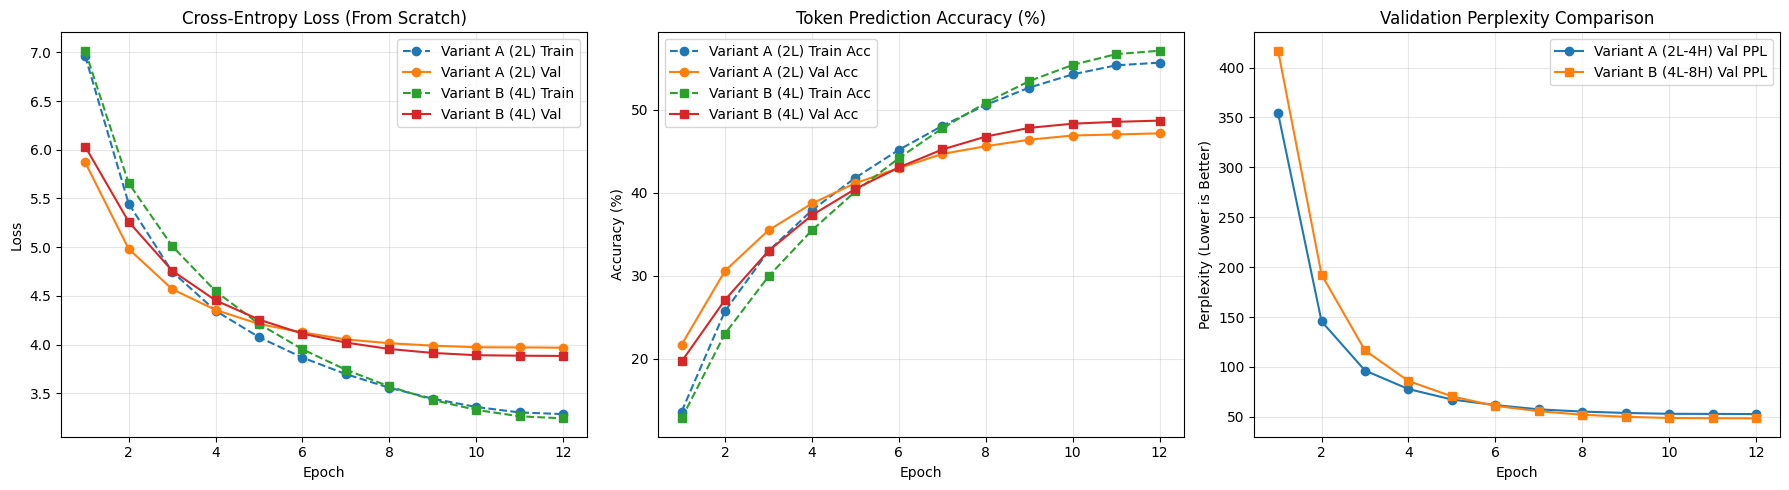

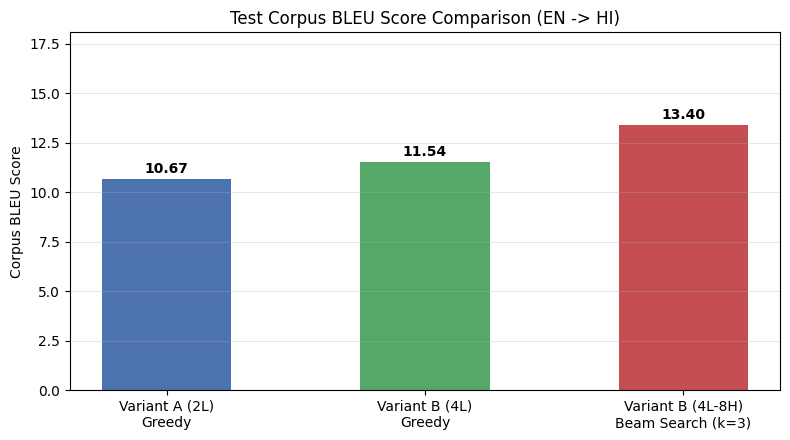

,English Source,Reference Hindi,Variant A (Greedy),Variant B (Greedy),Variant B (4L-8H) (Beam k=3)
0,He started a new method of writing about his i...,उन्होंने हिन्दी कहानी में आदर्शोन्मुख यथार्थवा...,उन्होंने अपने आदर्श के बारे में लिखने का एक नय...,उन्होंने अपने आदर्श जीवन के बारे में एक नए तरी...,उन्होंने अपने उपन्यास के बारे में एक नया तरीका...
1,Dutta has reportedly asked his heroes to sport...,"बताते हैं , दत्ता ने इन नायकों से कह दिया है क...",डलीज़ के नायर के माफ के मापदंड़ के लिए सुस्त स...,अभी तक उनके नायकों को माकना के माकलेट को मांगे...,यह बात भी साफ है कि उनके नायकों को पालने के लि...
2,"Indeed , nature itself has provided some answe...","वास्तव में , प्रकृति ने स्वयं इन प्रश्नों के क...","वास्तव में , प्रकृति ने इन प्रश्नों के उत्तर द...","वास्तव में , प्रकृति ने इन प्रश्नों के उत्तर द...","वास्तव में , प्रकृति ने इन प्रश्नों के उत्तर द..."
3,"and when the gunfire went off,","और जब बंदूक दगी,","और जब बंट गया ,","और जब बंदूक की आग से बाहर गया ,","और जब बंदूक की आग बुझाने लगी ,"
4,The Cooper Engineering Company and Kirloskar B...,"युद्ध से पहले , कपूर इंजीनियरिंग कंपनी और किर्...",कोक ने युद्ध से पहले ही कोयला और किशोर संयुगल ...,कोलोरोकार्ता इंस्टालर एंड किलऋसके युद्ध से पहल...,कोलोरोकार्ता इंस्टालर कंपनी तथा किशोर ने युद्ध...
5,It had warned the RBI as far back as 1997 that...,बीआइएस ने रिज़र्व बैंक को 1997 में ही आगाह कर ...,उन्हें चेतावनी दी थी कि रास्तों के नाम को 1997...,उन्हें रिजर्व ने 1997 तक ही कहा था कि सोने की ...,उन्होंने 1997 तक सेलूलर को चेतावनी दी थी कि सो...
6,Can you believe that prior to this reform -,क्या आप विश्वास कर सकते कि इस सुधार को करने से...,क्या आप इस सुधार से पहले विश्वास कर सकते हैं -,क्या आप मानते हैं कि इस सुधार से पहले -,क्या आप मानते हैं कि इस सुधार से पहले -
7,Mental illness targets,मानसिक रोग संबंधित लक्ष्य,मानसिक बीमारी,मानसिक रोग,मानसिक रोग


In [ ]:
# 1. Side-by-side Loss, Masked Token Accuracy (%), and Perplexity comparison curves
epochs_range = range(1, EPOCHS + 1)
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Panel 1: Cross-Entropy Loss
axes[0].plot(epochs_range, hist_a["train_loss"], "--o", label="Variant A (2L) Train")
axes[0].plot(epochs_range, hist_a["val_loss"], "-o", label="Variant A (2L) Val")
axes[0].plot(epochs_range, hist_b["train_loss"], "--s", label="Variant B (4L) Train")
axes[0].plot(epochs_range, hist_b["val_loss"], "-s", label="Variant B (4L) Val")
axes[0].set_title("Cross-Entropy Loss (From Scratch)")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Loss")
axes[0].legend()
axes[0].grid(True, alpha=0.3)

# Panel 2: Masked Next-Token Accuracy (%)
axes[1].plot(epochs_range, hist_a["train_acc"], "--o", label="Variant A (2L) Train Acc")
axes[1].plot(epochs_range, hist_a["val_acc"], "-o", label="Variant A (2L) Val Acc")
axes[1].plot(epochs_range, hist_b["train_acc"], "--s", label="Variant B (4L) Train Acc")
axes[1].plot(epochs_range, hist_b["val_acc"], "-s", label="Variant B (4L) Val Acc")
axes[1].set_title("Token Prediction Accuracy (%)")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Accuracy (%)")
axes[1].legend()
axes[1].grid(True, alpha=0.3)

# Panel 3: Validation Perplexity
axes[2].plot(epochs_range, hist_a["val_ppl"], "-o", color="#1f77b4", label="Variant A (2L-4H) Val PPL")
axes[2].plot(epochs_range, hist_b["val_ppl"], "-s", color="#ff7f0e", label="Variant B (4L-8H) Val PPL")
axes[2].set_title("Validation Perplexity Comparison")
axes[2].set_xlabel("Epoch")
axes[2].set_ylabel("Perplexity (Lower is Better)")
axes[2].legend()
axes[2].grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig("unit3_training_metrics_comparison.png", dpi=150)
plt.show()

# 2. Bar chart comparing Corpus BLEU across architectures and decoding strategies
plt.figure(figsize=(8, 4.5))
labels = ["Variant A (2L)\nGreedy", "Variant B (4L)\nGreedy", f"{winner_name}\nBeam Search (k=3)"]
scores = [bleu_a_greedy, bleu_b_greedy, bleu_win_beam]
colors = ["#4C72B0", "#55A868", "#C44E52"]

bars = plt.bar(labels, scores, color=colors, width=0.5)
for bar, score in zip(bars, scores):
    plt.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 0.3, f"{score:.2f}", ha="center", fontweight="bold")

plt.title("Test Corpus BLEU Score Comparison (EN -> HI)")
plt.ylabel("Corpus BLEU Score")
plt.ylim(0, max(scores) * 1.2 + 2)
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.savefig("unit3_bleu_benchmark.png", dpi=150)
plt.show()

# 3. Qualitative inspection table comparing model outputs against reference translations
samples_table = pd.DataFrame({
    "English Source": [eval_subset[i]["english_sentence"] for i in range(8)],
    "Reference Hindi": refs[:8],
    "Variant A (Greedy)": preds_a_greedy[:8],
    "Variant B (Greedy)": preds_b_greedy[:8],
    f"{winner_name} (Beam k=3)": preds_win_beam[:8],
})
display(samples_table)